Question 2.1 Two normalisations of the coordinates are compared. Both translate the origin to landmark 27, which 
removes the position of the face in the image. The first divides by the inter-ocular distance d, the 
distance between landmarks 36 and 45 in the same frame:

x′k= (xk−x27)/d ,y′k= (yk−y27)/d ,    

d =√(( x45−x36)^2+( y45− y36)^2)

The second divides by the dimensions of the image, 1280 × 720 pixels:

x′k= (xk−x27)/1280 , y′k= (yk− y27)/720

Compare the two through the variability between actors in the neutral expression: for each 
normalisation, compute the median width of the mouth (the distance between landmarks 48 and 54) 
in the neutral videos of each actor, and the coefficient of variation of these 20 medians. Which 
normalisation leaves less variation between actors, and why? What does dividing x by 1280 and y by 
720 do to the geometry of the face? All the remaining tasks use the normalisation by d.

In [4]:
import numpy as np
import pandas as pd

df = pd.read_parquet("t1.1.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

df = df[~df["video"].isin(testIndex["video"])]

# video names are like "01-01-01-01-01-01-01.csv"
neutral = df[df["video"].astype(str).str.split("-").str[2].eq("01")].copy()

neutral["actor"] = neutral["video"].str.replace(".csv", "", regex=False).str[-2:]

#d =√(( x45−x36)^2+( y45− y36)^2)
d = np.sqrt((neutral["x_45"] - neutral["x_36"])**2 + (neutral["y_45"] - neutral["y_36"])**2)

#x′k= (xk−x27)/d ,y′k= (yk−y27)/d  ("compute the median width of the mouth (the distance between landmarks 48 and 54)")
x48_d = (neutral["x_48"] - neutral["x_27"]) / d
y48_d = (neutral["y_48"] - neutral["y_27"]) / d
x54_d = (neutral["x_54"] - neutral["x_27"]) / d
y54_d = (neutral["y_54"] - neutral["y_27"]) / d

#x′k= (xk−x27)/1280 , y′k= (yk− y27)/720
x48_img = (neutral["x_48"] - neutral["x_27"]) / 1280
y48_img = (neutral["y_48"] - neutral["y_27"]) / 720
x54_img = (neutral["x_54"] - neutral["x_27"]) / 1280
y54_img = (neutral["y_54"] - neutral["y_27"]) / 720

#Mouth width = distance between landmarks 48 and 54, with each normalisation
neutral["width_d"]   = np.sqrt((x54_d - x48_d)**2 + (y54_d - y48_d)**2)
neutral["width_img"] = np.sqrt((x54_img - x48_img)**2 + (y54_img - y48_img)**2)

#median per actor
medians = neutral.groupby("actor")[["width_d", "width_img"]].median()
print(medians)

#Coefficient of variation = standard deviation / mean, of those 20 medians
cv_d   = medians["width_d"].std()   / medians["width_d"].mean()
cv_img = medians["width_img"].std() / medians["width_img"].mean()
print("CV with d:        ", cv_d)
print("CV with image size:", cv_img)



        width_d  width_img
actor                     
02     0.566075   0.090233
03     0.624451   0.097635
04     0.611065   0.095907
05     0.619302   0.108878
06     0.615028   0.096501
07     0.637391   0.104304
08     0.613624   0.094383
09     0.569194   0.095751
10     0.591432   0.095975
11     0.627349   0.111028
12     0.551322   0.088065
13     0.621648   0.098018
14     0.615739   0.100030
15     0.637833   0.108186
18     0.608866   0.107025
19     0.628179   0.106243
20     0.596602   0.089660
21     0.559526   0.081565
22     0.578067   0.101290
23     0.642346   0.103130
CV with d:         0.04556682175548994
CV with image size: 0.0785016760874476


Normalising by the inter-ocular distance d leaves less variation between actors: the coefficient of variation of the 20 median mouth widths is 0.046, against 0.079 when dividing by the image size.

The reason is scale. The size of a face in the image depends on how far the actor sits from the camera, and not on the expression. The inter-ocular distance d is measured on the same face, so it grows and shrinks with the face. Dividing the mouth width by d cancels this effect and leaves the width relative to the face. Dividing by 1280 and 720 divides every actor by the same constant, so the differences in scale between actors are kept.

Dividing x by 1280 and y by 720 scales the two axes by different factors, so the face is deformed. The normalisation by d scales both axes by the same factor, so the shape of the face is preserved. It is used in all the remaining tasks.

Question 2.2
Consider the frames of all development videos together, one row per frame. Draw a box plot per emotion of one normalised coordinate of your choice, for example x_54. Then, for every normalised coordinate and every emotion, compute the density of outliers
ρ = 100 × (no \n)
where no is the number of frames flagged and n the number of frames, using (a) the interquartile range (IQR) with Tukey's fences, the rule of the box plot, which flags the values below Q1 − 1.5 IQR or above Q3 + 1.5 IQR, and (b) the z-score with k = 3 and k = 4. For each emotion, report the mean and the standard deviation of ρ over the coordinates. Comment on the differences between the two rules and between emotions.

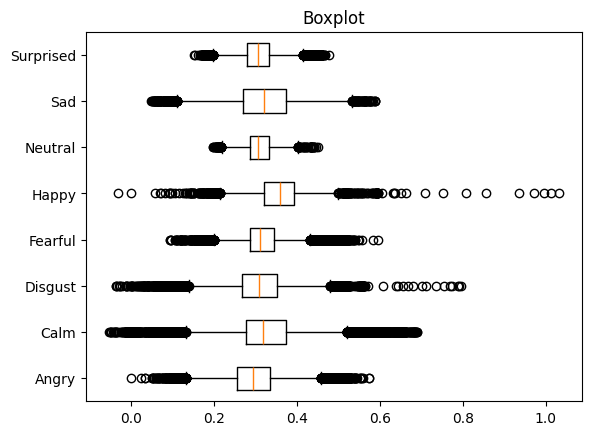

Angry -> IQR: 0.08135414761829951
Calm -> IQR: 0.09721108189827665
Disgust -> IQR: 0.08545456982306165
Fearful -> IQR: 0.05785720686845547
Happy -> IQR: 0.0713364419774683
Neutral -> IQR: 0.04613688270023797
Sad -> IQR: 0.10525619236189104
Surprised -> IQR: 0.054266242193123426
136 coordinates
IQR Tukey:
 Mean: emotion
Angry        3.002687
Calm         3.933789
Disgust      3.691104
Fearful      2.690651
Happy        1.895115
Neutral      0.684378
Sad          1.611813
Surprised    2.478892
dtype: float64
 Std: emotion
Angry        1.764197
Calm         3.236581
Disgust      3.175588
Fearful      1.944793
Happy        1.175044
Neutral      0.869442
Sad          1.458626
Surprised    1.938397
dtype: float64

Z-score (k=3):
 Mean: emotion
Angry        0.944421
Calm         0.471825
Disgust      0.826235
Fearful      0.790710
Happy        0.799111
Neutral      0.234498
Sad          0.492174
Surprised    0.718432
dtype: float64
 Std: emotion
Angry        0.514838
Calm         0.446507
Dis

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dados = pd.read_parquet("t1.1.gzip")
testIndex = pd.read_parquet("testIndex.gzip")
videoTable = pd.read_parquet("t1.2.gzip")
dados = dados[~dados["video"].isin(testIndex["video"])].copy()

d = np.sqrt((dados["x_45"] - dados["x_36"])**2 + (dados["y_45"] - dados["y_36"])**2)
dados["x54_d"] = (dados["x_54"] - dados["x_27"]) / d

#group by checking the video name in the videoTable, and getting the emotion from there
groups = dados.groupby(dados["video"].map(videoTable.set_index("video")["emotion"]))["x54_d"].apply(list)
#label the y-axis with the emotion names in the videoTable, in the order they appear in the groups
bp = plt.boxplot(groups,vert= False, labels=groups.index)
plt.title("Boxplot")

plt.show()

for i, box in enumerate(bp['boxes']):
    x_data = box.get_xdata()
    q1 = x_data[0]
    q3 = x_data[2]
    print(f"{groups.index[i]} -> IQR: {q3 - q1}")

cols = {}
for k in range(68):
    cols[f"x_{k}"] = (dados[f"x_{k}"] - dados["x_27"]) / d
    cols[f"y_{k}"] = (dados[f"y_{k}"] - dados["y_27"]) / d

norm = pd.DataFrame(cols)
coords = list(norm.columns)
print(len(coords), "coordinates")
#print(norm)
norm["emotion"] = dados["video"].map(videoTable.set_index("video")["emotion"])
norm["actor"] = dados["video"].map(videoTable.set_index("video")["actor"])
norm["video"] = dados["video"]

#IQR range with Tukey fences.
def flag_iqr(g):
    q1 = g.quantile(0.25)
    q3 = g.quantile(0.75)
    iqr = q3 - q1
    return (g < q1 - 1.5 * iqr) | (g > q3 + 1.5 * iqr)   # True/False per value
    
def rho_iqr(g):
    return 100 * flag_iqr(g).mean()                              # % of frames flagged, per coordinate

#z score k=3 and k=4
def rho_z(g, k):
    z = (g - g.mean()) / g.std()
    outlier = z.abs() > k
    return 100 * outlier.mean()

by_emotion = norm.groupby("emotion")
#apply the functions to each group, for each coordinate
IQR_Tukey = by_emotion[coords].apply(rho_iqr)
Z_k3 = by_emotion[coords].apply(rho_z, k=3)
Z_k4 = by_emotion[coords].apply(rho_z, k=4)

#mean and standart deviantion of the density of outliers per emotion
print(f"IQR Tukey:\n Mean: {IQR_Tukey.mean(axis=1)}\n Std: {IQR_Tukey.std(axis=1)}\n")
print(f"Z-score (k=3):\n Mean: {Z_k3.mean(axis=1)}\n Std: {Z_k3.std(axis=1)}\n")
print(f"Z-score (k=4):\n Mean: {Z_k4.mean(axis=1)}\n Std: {Z_k4.std(axis=1)}\n")


Tukey's fences flag a greater density of outliers than the z-score, regardless of the emotion: IQR flags between 0.6% and 4.0% of frames, z-score with k=3 between 0.2% and 1.0%, and k=4 between 0.005% and 0.4%. The IQR rule is based on the quartiles, so it is stricter on frames that are only moderately far from the centre, while the z-score depends on the mean and standard deviation, which are themselves inflated by the extreme frames.

Neutral has the lowest density of outliers with all three rules. Calm, Disgust and Angry have the highest IQR densities. Calm drops the most when going to z-score, so its outliers are mostly moderate, whereas Happy keeps the highest density at k=4, which points to a few very extreme frames. For Calm and Disgust the standard deviation across coordinates is as large as the mean, so their outliers are concentrated in some coordinates; Angry has a similar mean but a lower standard deviation, so its outliers are spread more evenly. A flagged frame is an extreme value, not necessarily a tracking error, since strong expressions legitimately produce extremes.

Question 2.3 For one coordinate and one emotion, find which actors and which videos the flagged frames come 
from. Are they errors of the tracker or legitimate, extreme expressions? Should they be removed or 
corrected before the features are computed? Justify.

816 flagged of 18742 frames
         count      mean  median   min   max
flagged                                     
False    17926  0.978932    0.98  0.88  0.98
True       816  0.978346    0.98  0.93  0.98
                          flagged  frames  min_confidence actor
video                                                          
01-01-07-02-01-01-05.csv      124     130            0.93    05
01-01-07-02-01-02-05.csv      106     117            0.98    05
01-01-07-02-02-02-05.csv       95     136            0.98    05
01-01-07-02-01-01-03.csv       93     123            0.98    03
01-01-07-02-02-01-03.csv       62     115            0.98    03
01-01-07-02-02-01-20.csv       48     142            0.98    20
01-01-07-01-01-01-14.csv       47     112            0.98    14
01-01-07-01-01-02-03.csv       42     119            0.98    03
01-01-07-01-02-02-14.csv       35     112            0.98    14
01-01-07-02-01-02-06.csv       34     117            0.93    06
01-01-07-02-01-02-03.csv

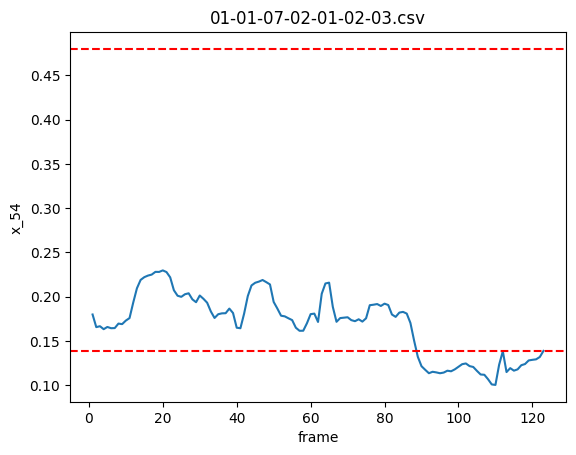

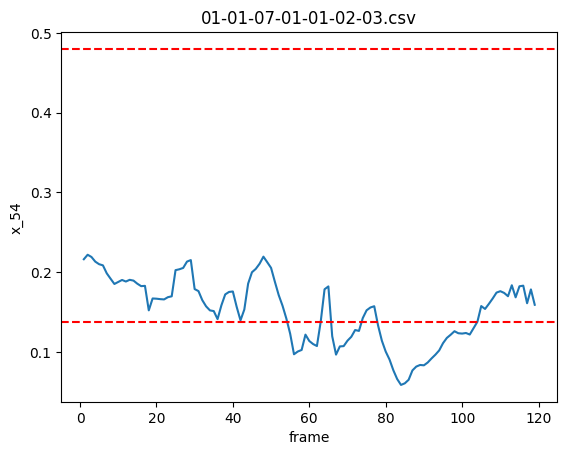

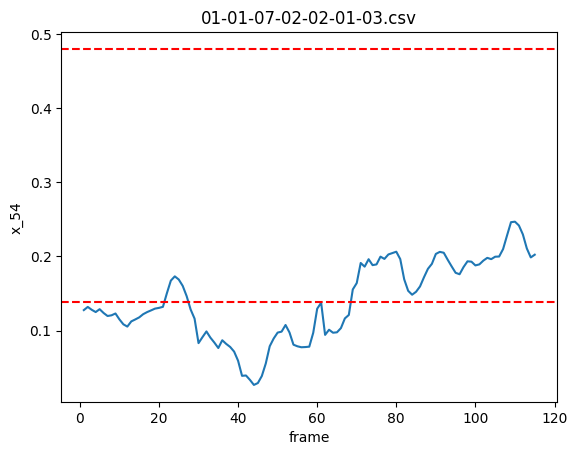

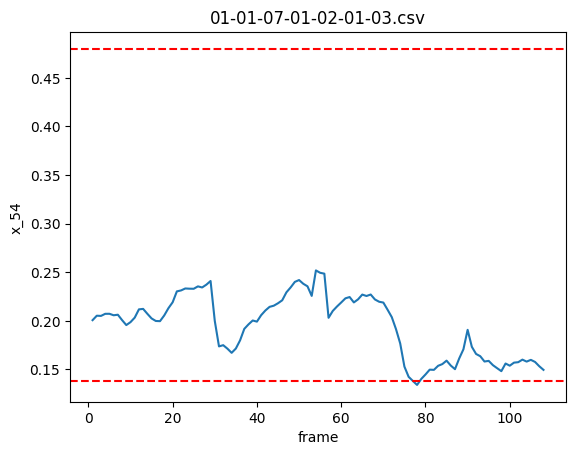

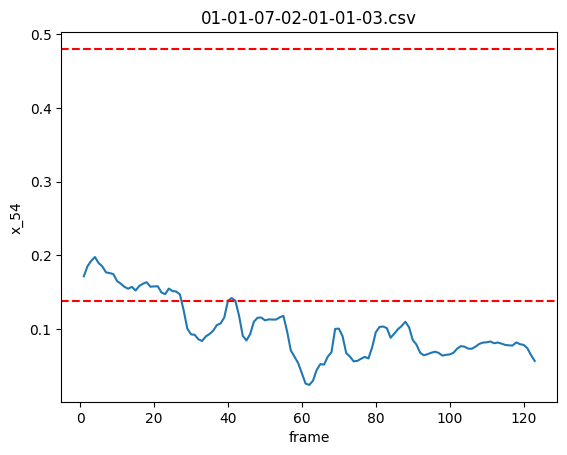

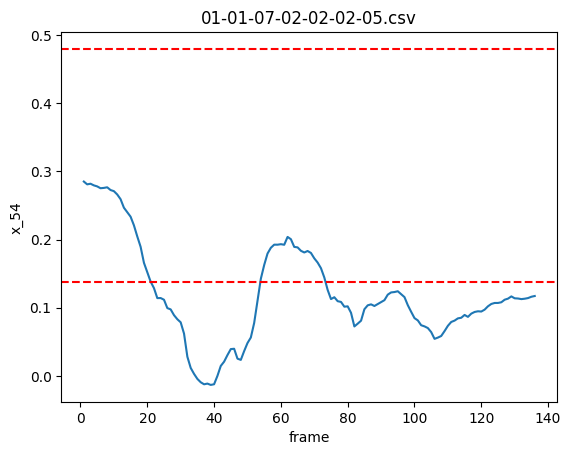

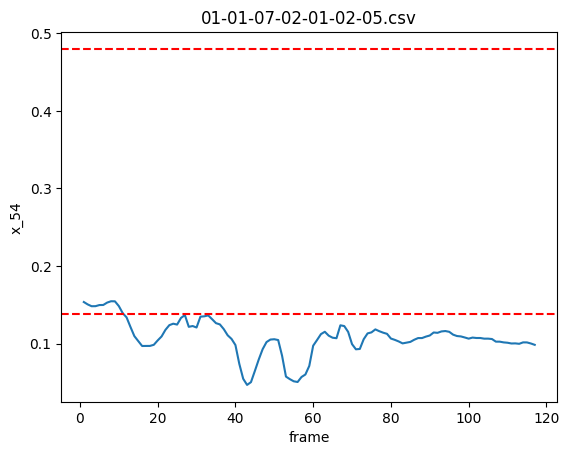

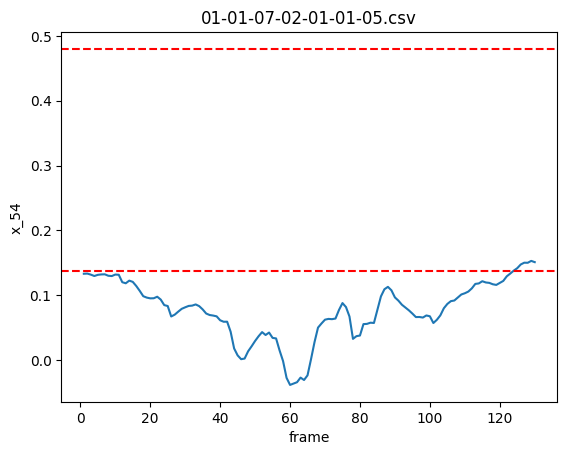

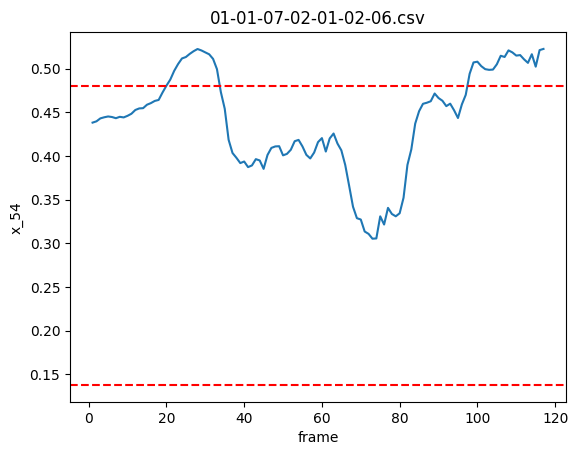

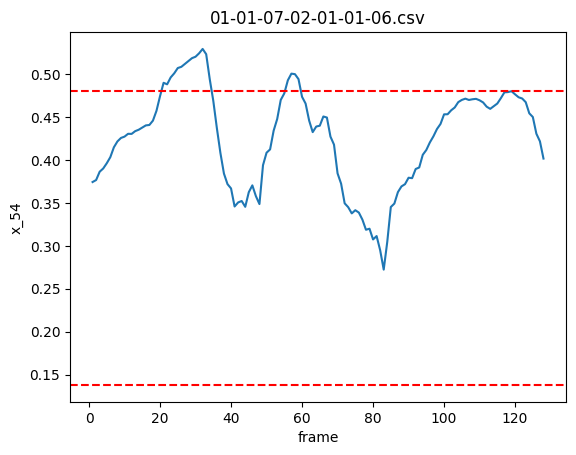

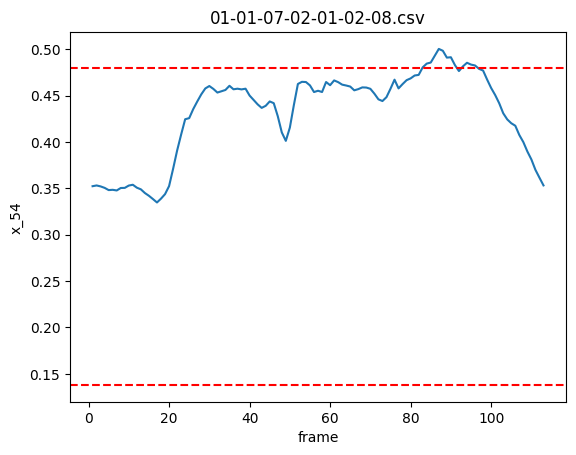

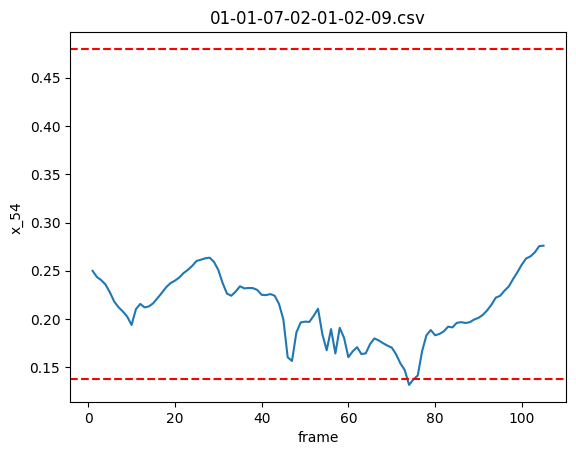

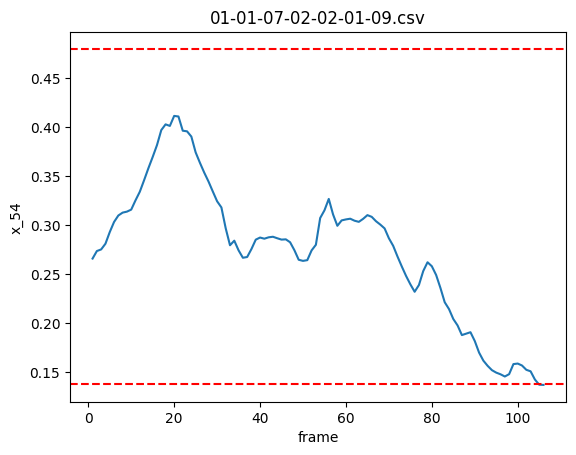

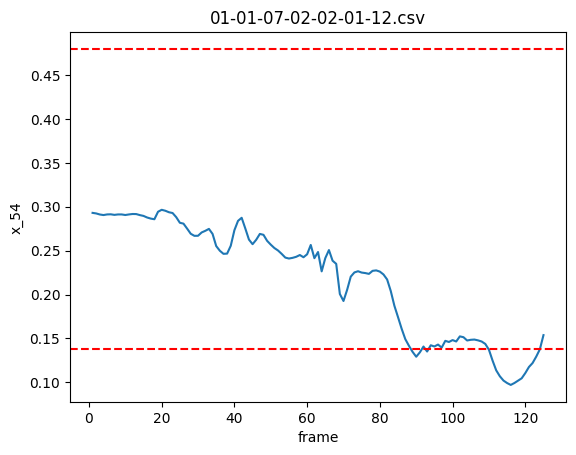

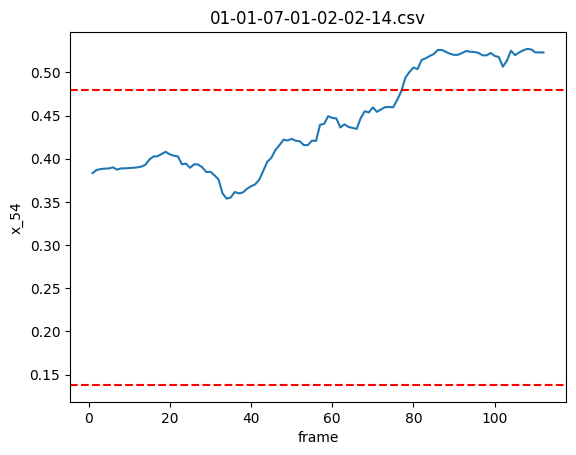

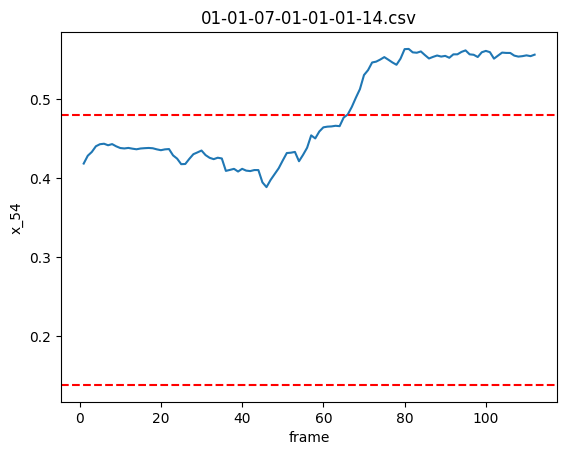

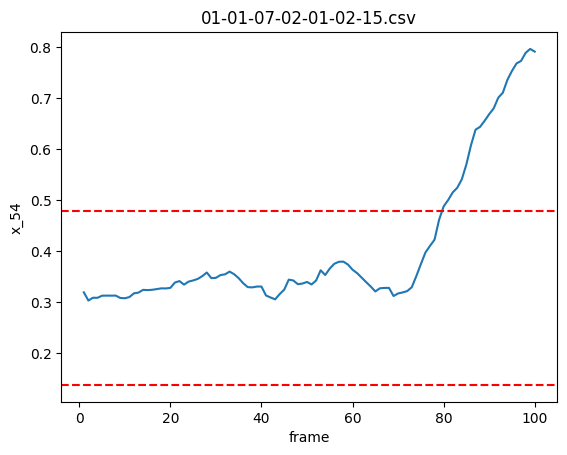

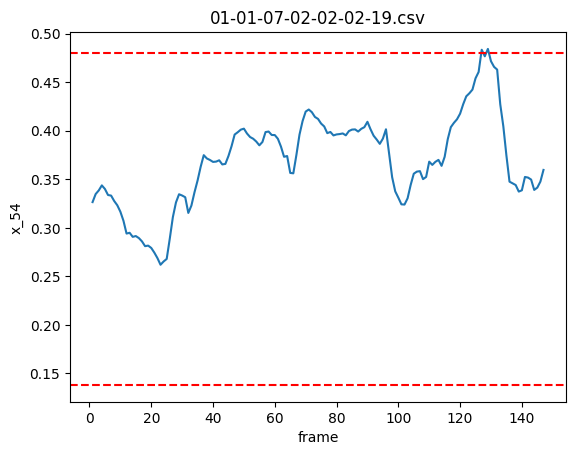

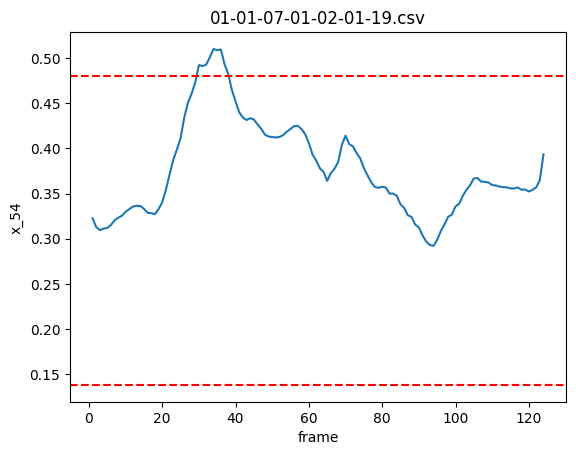

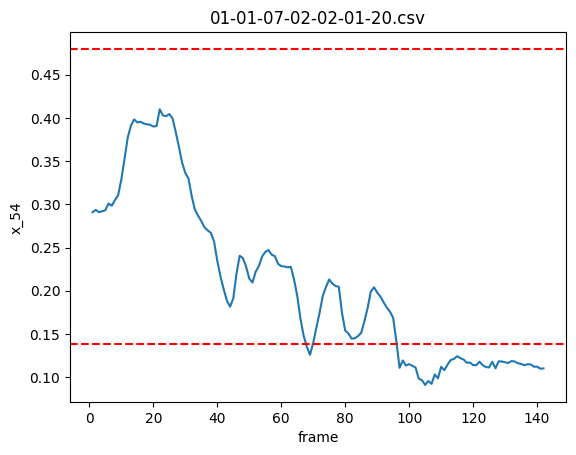

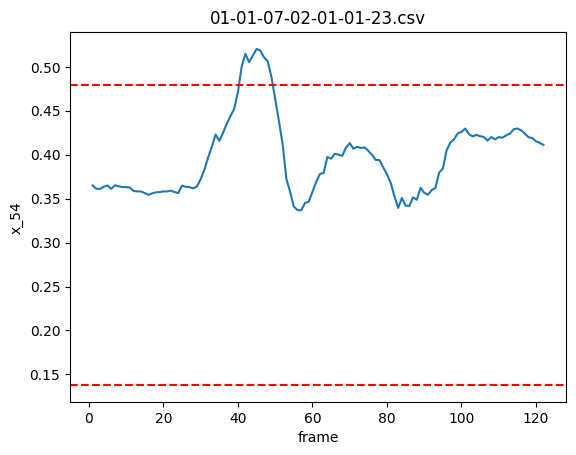

In [6]:
chosen_emotion = "Disgust"
chosen_coor = "x_54"
norm["confidence"] = dados["confidence"]

sub = norm[norm["emotion"] == chosen_emotion].copy()           # frames of the chosen emotion



q1, q3 = sub[chosen_coor].quantile([0.25, 0.75])
iqr = q3 - q1
sub["flagged"] = (sub[chosen_coor] < q1 - 1.5 * iqr) | (sub[chosen_coor] > q3 + 1.5 * iqr)
print(sub["flagged"].sum(), "flagged of", len(sub), "frames")

# Compare confidence in flagged and unflagged frames
print(
    sub.groupby("flagged")["confidence"]
       .agg(["count", "mean", "median", "min", "max"])
)

# flagged frames per video (only videos with at least one)
per_video = sub.groupby("video").agg(flagged=("flagged", "sum"), frames=("flagged", "size"), min_confidence=("confidence", "min"))
per_video = per_video[per_video["flagged"] > 0].sort_values("flagged", ascending=False)
per_video["actor"] = per_video.index.map(videoTable.set_index("video")["actor"])
print(per_video)

# flagged frames per actor
print(per_video.groupby("actor")["flagged"].agg(videos="count", frames="sum")
    .sort_values("frames", ascending=False))

per_video = per_video.sort_values("actor", ascending=True)

for v in per_video.index:
    #v = per_video.index[i]
    rows = (norm["video"] == v).to_numpy()
    plt.plot(dados.loc[rows, "frame"].to_numpy(), norm.loc[rows, chosen_coor].to_numpy())
    plt.axhline(q3 + 1.5 * iqr, color="r", ls="--")      # upper fence (add the lower one if needed)
    plt.axhline(q1 - 1.5 * iqr, color="r", ls="--")      # lower fence
    plt.xlabel("frame"); plt.ylabel(chosen_coor); plt.title(v); plt.show()


For x_54 and Disgust, 816 of 18742 frames are flagged by Tukey's fences, coming from 21 videos of 11 actors. They are concentrated in actors 05 and 03 (68 % of the flagged frames). In the plotted videos the coordinate varies smoothly over many consecutive frames, with no isolated jumps, so they do not look like random tracker glitches. Confidence is no help here: it is the same in flagged and unflagged frames (mean 0.978 against 0.979).

In the video plots of actors 03 and 05 the coordinate is consistently low, while for actors 06, 08 and 14 it is consistently high. This suggests that the actor's head pose and morphology, and not only the expression, may be responsible for part of the outliers, but this is a hypothesis that these plots cannot confirm. They also do not rule out a systematic tracking error in some videos (for example, in video 01-01-07-02-01-02-15 the coordinate rises to about 0.8), only random glitches.

I would not remove these frames. Removing them would bias the data away from strong expressions of the strongest emotions, and possibly from different head poses and morphologies. I would not correct them either, since nothing shows that the values are wrong and there is no reference for what the correct landmark position would be.

Question 2.4
Apply k-means to the pair (x_54, y_54) of all development frames, with 2, 4 and 8 clusters, and flag as outliers the frames whose distance to the centroid of their cluster exceeds the mean plus three standard deviations of the distances within that cluster. Compare with 2.2 and illustrate with two- dimensional plots. Optionally, repeat with DBSCAN on a random sample of 20 000 frames; on all frames, its memory requirements can exceed those of a laptop.

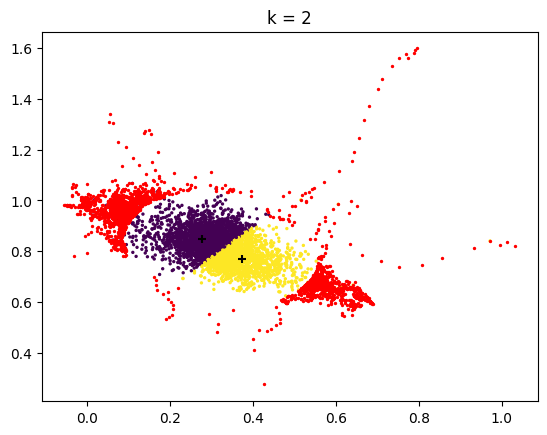

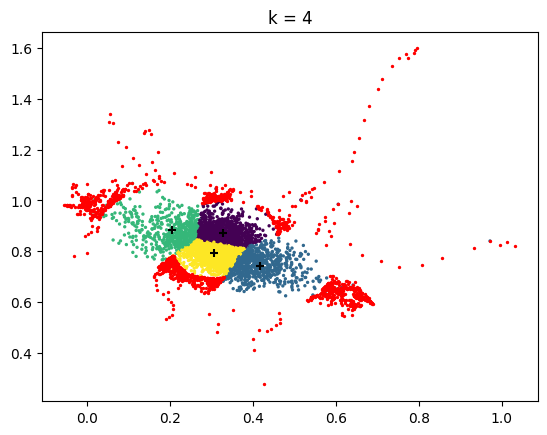

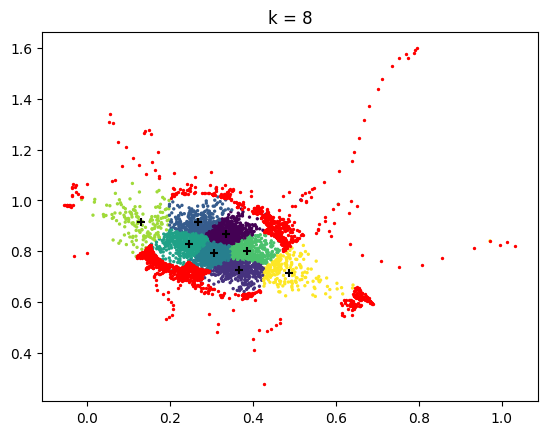


k-means k=2, %outliers per emotion:


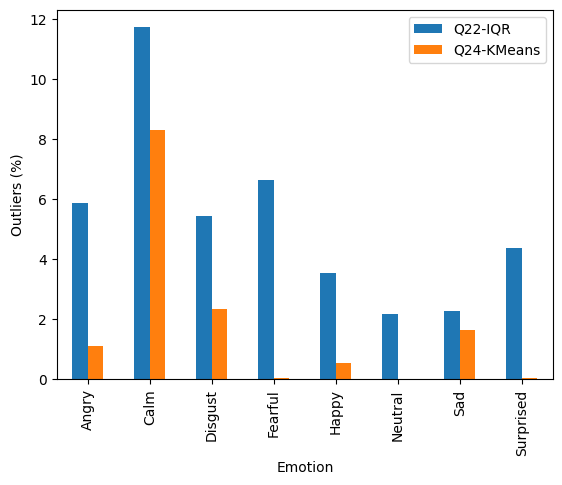


k-means k=4, %outliers per emotion:


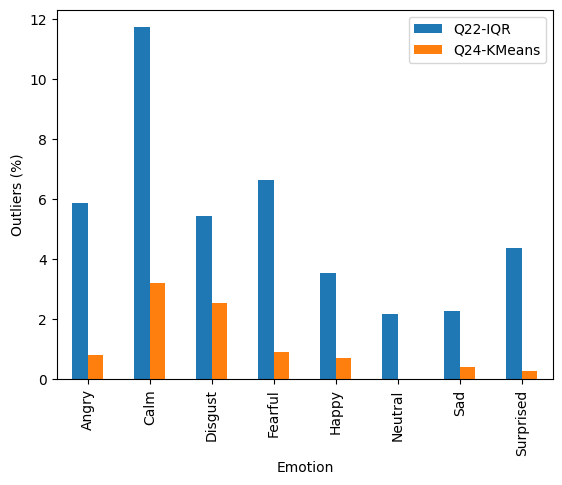


k-means k=8, %outliers per emotion:


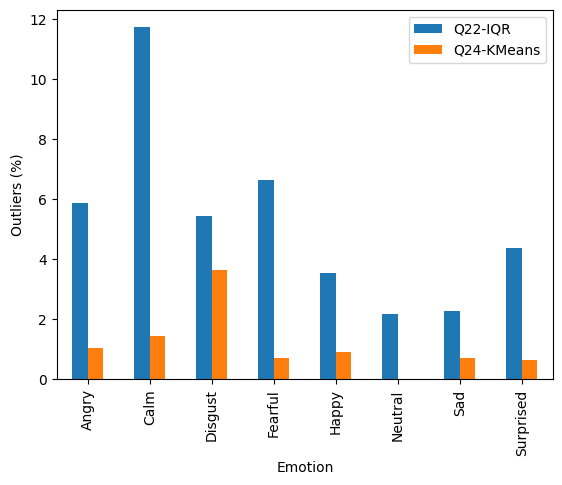

DBSCAN: 14 outliers


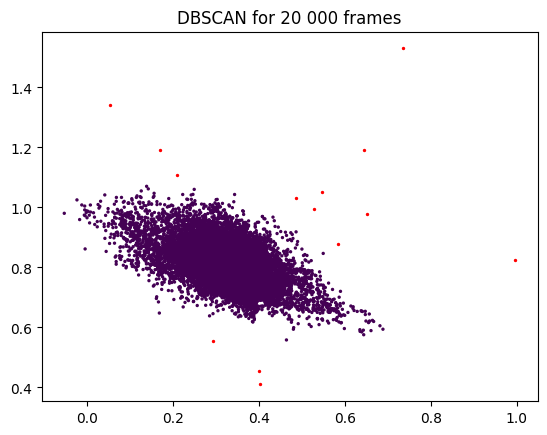

In [7]:
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

dados["x54_d"] = (dados["x_54"] - dados["x_27"]) / d
dados["y54_d"] = (dados["y_54"] - dados["y_27"]) / d

pts = dados[["x54_d", "y54_d"]]
X = pts.to_numpy();


results = {}
for i in (2,4,8):
    out = np.zeros(len(X), dtype=bool)
    kmeans = KMeans(n_clusters= i, random_state=0, n_init="auto").fit(X)
    centroides = kmeans.cluster_centers_
    labels = kmeans.labels_
    distances = np.linalg.norm(X - centroides[labels], axis=1)

    for cluster in range(i):
        b = labels == cluster
        lim = distances[b].mean () + 3 * distances[b].std()
        out[b] = lim < distances[b]
        #print(f"k= {i}, cluster: {cluster} - outliers: {out[b].sum()} in {b.sum()} frames")

    results[i] = (out,centroides)
    plt.scatter(X[::30, 0], X[::30, 1], c=labels[::30], s=2)     
    plt.scatter(X[out, 0], X[out, 1], c="red", s=2)            
    plt.scatter(centroides[:, 0], centroides[:, 1], c="black", marker="+", s=30)   
    plt.title(f"k = {i}")
    plt.show()
        
#print(results)

#compare with 2.2
n = norm.reset_index(drop=True)
f = n.groupby("emotion")[["x_54", "y_54"]].transform(flag_iqr)
ref = f["x_54"].to_numpy().astype(bool) | f["y_54"].to_numpy().astype(bool)
emo = norm["emotion"].to_numpy()

for k, (out, cent) in results.items():
    print(f"\nk-means k={k}, %outliers per emotion:")
    outliers_24 = ((100 * pd.Series(out).groupby(emo).mean()).round(2))

    comp = pd.DataFrame({
        "Q22-IQR": (100 * pd.Series(ref).groupby(emo).mean()).round(2),
        "Q24-KMeans": outliers_24
    })
    comp.plot(kind="bar")
    plt.ylabel("Outliers (%)")
    plt.xlabel("Emotion")
    plt.legend()
    plt.show()


#DBSCAN
rng = np.random.default_rng(0)
index = rng.choice(len(X), size=20000, replace=False)
X_db = X[index]

dbscan = DBSCAN(eps=0.05, min_samples=10).fit(X_db)

outliers = dbscan.labels_ == -1
print(f"DBSCAN: {outliers.sum()} outliers")

plt.scatter(X_db[~outliers, 0], X_db[~outliers, 1], c=dbscan.labels_[~outliers], s=2)     
plt.scatter(X_db[outliers, 0], X_db[outliers, 1], c="red", s=2) 
plt.title("DBSCAN for 20 000 frames")
plt.show()

The IQR identified a significantly higher percentage of outliers than K-Means, a difference that persisted across the various numbers of clusters (k) tested. While the IQR uses each coordinate individually to identify outliers, K-Means considers the distance of both coordinates from the cluster center. We observed a high percentage of outliers for the 'Calm' emotion under both metrics when k=2 for K-Means. However, as the number of clusters increases, the number of outliers decreases significantly, resulting in low outlier percentages for all emotions. Such discrepancies between the two methods are expected, given that the IQR identifies extreme values ​​within each individual coordinate, whereas K-Means detects points that are distant from the centroid.

Question 2.5
Write a function that receives an array, a rate, k and a random generator, selects at random a fraction of the samples equal to the rate, and replaces each selected value by
p=μ+s·k·σ+q
where μ and σ are the mean and the standard deviation of the array before the injection, s is −1 or +1 with equal probability, and q is drawn uniformly from [0, σ). Inject outliers into 2 % of the frames of y_57, with k = 3 and a fixed seed, and keep the original values and the positions of the injected samples.

In [8]:
def create_outliers(a, rate, k, random_generate):
    a = np.asarray(a, dtype=float).copy()
    original = a.copy()
    lenA = int(round(len(a) * rate))
    mean = original.mean()
    std = original.std()
    indicesChanged = random_generate.choice(len(a), size=lenA,replace= False)
    for i in indicesChanged:
        s = random_generate.choice([-1,1])
        q = random_generate.uniform(low = 0, high = std)
        a[i] = mean + s * k * std + q
    return original,a,indicesChanged

rng = np.random.default_rng(42)
dados["y57_d"] = (dados["y_57"] - dados["y_27"]) / d

y_original ,y_change,indicesChanged = create_outliers(dados["y57_d"], 0.02, 3, random_generate=rng)
dados["y57_d"] = y_change
print(f"Changed {len(indicesChanged)} frames of {len(y_original)} frames")
for i in indicesChanged:
    print(f"indice: {i} - {y_original[i]} -> {y_change[i]}")


Changed 2644 frames of 132176 frames
indice: 60330 - 1.0948677431328118 -> 0.8232938021150701
indice: 26305 - 0.9007194329187959 -> 0.7891915292217145
indice: 64303 - 1.1818571810409475 -> 1.2411381747178436
indice: 31021 - 0.9669318953514012 -> 1.2555004118827267
indice: 110384 - 1.0063678477616258 -> 0.7764665567322931
indice: 19564 - 0.95741335965897 -> 0.8224155550667482
indice: 96307 - 0.9913267468450513 -> 0.8045825583480941
indice: 43470 - 0.8403063546231871 -> 0.8366649037899683
indice: 3437 - 0.9139217496517807 -> 0.8284541976865601
indice: 10786 - 0.9363426805236027 -> 1.2272670539474317
indice: 72889 - 1.131796208809603 -> 1.2789169377334593
indice: 118329 - 1.090220944215343 -> 1.24124314040153
indice: 88144 - 1.0408917669042952 -> 0.8251123453161924
indice: 121215 - 0.9075054057770047 -> 0.8004893629926506
indice: 4993 - 1.0207204804329446 -> 0.8379161264575021
indice: 79880 - 1.0090784930206291 -> 1.2586518546545853
indice: 598 - 1.0196004188033376 -> 1.2409080840346094
i

Question 2.6
Detect the injected samples with the z-score and k = 3, computed on the contaminated variable. Report the recall and the precision of the detection with respect to the injected positions, and explain the result. Would a smaller k solve the problem, and at what cost?

In [9]:
mean = y_change.mean()
std = y_change.std()
ZScore = (y_change - mean)/ std

def calculate_metrics(k):
    flagZScore = np.abs(ZScore) > k

    real = np.zeros(len(y_change), dtype=bool)
    real[indicesChanged] = True 

    vp = (real & flagZScore).sum()
    fn = (real & ~flagZScore).sum()
    fp = (~real & flagZScore).sum()


    recall = (vp / (vp+fn)).round(2)
    precision = (vp / (vp + fp)).round(2)

    print(f"k={k}: Recall= {recall}, precision= {precision}")
    print("Outliers injetados:", real.sum())
    print("Outliers detetados:", flagZScore.sum())

calculate_metrics(3)

for value_k in (0.5,1,1.5,2,2.5):
    calculate_metrics(value_k)



k=3: Recall= 0.37, precision= 0.61
Outliers injetados: 2644
Outliers detetados: 1594
k=0.5: Recall= 1.0, precision= 0.03
Outliers injetados: 2644
Outliers detetados: 77473
k=1: Recall= 1.0, precision= 0.07
Outliers injetados: 2644
Outliers detetados: 36048
k=1.5: Recall= 1.0, precision= 0.18
Outliers injetados: 2644
Outliers detetados: 14478
k=2: Recall= 0.92, precision= 0.35
Outliers injetados: 2644
Outliers detetados: 6840
k=2.5: Recall= 0.66, precision= 0.54
Outliers injetados: 2644
Outliers detetados: 3250


Question 2.7
The lower lip moves with its neighbours. Fit a linear regression of y_57 on y_56 and y_58 (scikit- learn) and compute the residual of every frame. Flag the frames whose residual has a modified z- score [4]
Mi=(0.6745 ×(ri− med(r)))/ MAD
greater than 3.5 in absolute value, where ri is the residual of frame i, med(r) the median of the residuals and MAD their median absolute deviation. Report recall and precision. Why does this detector succeed where that of 2.6 fails? Why is a robust threshold used for the residuals?

In [10]:
from sklearn.linear_model import LinearRegression

x56_58 = np.column_stack([dados["y_56"].to_numpy(),dados["y_58"].to_numpy()])
y = np.asarray(y_change)

reg = LinearRegression().fit(x56_58, y)
r = y - reg.predict(x56_58)

med = np.median(r) 
mad = np.median(np.abs(r - med))
M = (0.6747 * (r - med)) / mad

flagFramesM = np.abs(M) > 3.5

real = np.zeros(len(y),dtype=bool)
real[indicesChanged] = True

vp = (real & flagFramesM).sum()
fn = (real & ~flagFramesM).sum()
fp = (~real & flagFramesM).sum()

recall = (vp / (vp + fn)).round(3)
precision = vp / (vp + fp).round(3)

print(f"Recall: {recall} // Precision: {precision}")
print(f"Outliers injetados: {real.sum()} // Outliers detetados: {flagFramesM.sum()}")

Recall: 0.387 // Precision: 0.7087378640776699
Outliers injetados: 2644 // Outliers detetados: 1442


Question 2.8
Replace the values flagged in 2.7 by (a) linear interpolation in time within the same video, (b) the prediction of the regression of 2.7, refitted without the flagged frames, and (c) the mean of the variable. Compare each with the original values through the mean absolute error at the injected positions. Which is best, and why? Which would you choose if the neighbouring landmarks had failed in the same frames?

In [47]:
y=np.asarray(y_change,dtype=float)
#a
Ya = y.copy()
video = dados["video"].to_numpy()
frame = dados["frame"].to_numpy()

for vid in np.unique(video):
    m = np.where(video == vid)[0]
    m = m[np.argsort(frame[m])] 
    n= flagFramesM[m]
    if n.any():
        Ya[m[n]] = np.interp(frame[m][n], frame[m][~n], y[m][~n])

#b
reg = LinearRegression().fit(x56_58[~flagFramesM], y[~flagFramesM])
Yb = y.copy()
Yb[flagFramesM] = reg.predict(x56_58[flagFramesM])

#c
Yc = y.copy()
mean = Yc[~flagFramesM].mean()
Yc[flagFramesM] = mean

pos = np.asanyarray(indicesChanged)
dfOrigCont = pd.DataFrame({
    "position": pos,
    "contaminated": y[pos],
    "original": y_original[pos],
    "a": Ya[pos],
    "b": Yb[pos],
    "c": Yc[pos],
    "AE contaminated": np.abs(y[pos] - y_original[pos]),
    "AE (a)": np.abs(Ya[pos] - y_original[pos]),
    "AE (b)": np.abs(Yb[pos] - y_original[pos]),
    "AE (c)": np.abs(Yc[pos] - y_original[pos]),
})
print(dfOrigCont)
print(f"MAE: a-> {dfOrigCont['AE (a)'].mean()},b-> {dfOrigCont['AE (b)'].mean()},c-> {dfOrigCont['AE (c)'].mean()}")

      position  contaminated  original         a         b         c  \
0        60330      0.823294  1.094868  0.823294  0.823294  0.823294   
1        26305      0.789192  0.900719  0.789192  0.789192  0.789192   
2        64303      1.241138  1.181857  1.241138  1.241138  1.241138   
3        31021      1.255500  0.966932  0.951919  0.976331  0.986547   
4       110384      0.776467  1.006368  0.776467  0.776467  0.776467   
...        ...           ...       ...       ...       ...       ...   
2639     57232      1.235873  1.102629  1.090969  0.969401  0.986547   
2640     58007      1.241536  0.946393  0.941901  0.952309  0.986547   
2641     86517      1.228173  1.015356  1.019084  0.980121  0.986547   
2642    102297      1.271947  0.979253  1.271947  1.271947  1.271947   
2643     11796      0.805954  1.001362  0.805954  0.805954  0.805954   

      AE contaminated    AE (a)    AE (b)    AE (c)  
0            0.271574  0.271574  0.271574  0.271574  
1            0.111528  0.11